# 02 · Text Statistics — length, words, punctuation, capitals
**Part of the [Sentiment Analysis on IMDB 50K](README.md) project.** Previous: [01 Overview](01_dataset_overview_and_quality.ipynb).

We engineer simple numeric features from raw text and check whether they differ between positive and negative reviews. This is classic EDA for NLP.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import re, string
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style='whitegrid')
df = pd.read_csv('data/imdb_dedup.csv')
print(df.shape)

(49582, 3)


In [2]:
PAL = {'negative':'#d9534f','positive':'#5cb85c'}
df.head(3)

,review,sentiment,label
0,One of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,positive,1
2,I thought this was a wonderful way to spend ti...,positive,1


## 1. Build text-statistic features

First remove `<br />` tags for fair counting (full cleaning comes in notebook 04).

In [3]:
df['text'] = df['review'].str.replace(r'<[^>]+>', ' ', regex=True)
df['text'] = df['text'].str.replace(r'\s+', ' ', regex=True).str.strip()
df[['text']].head(2)

,text
0,One of the other reviewers has mentioned that ...
1,A wonderful little production. The filming tec...


In [4]:
df['n_chars']      = df['text'].str.len()

In [5]:
df['n_words']      = df['text'].str.split().str.len()

In [6]:
df['n_sentences']  = df['text'].str.count(r'[.!?]+') .clip(lower=1)

In [7]:
df['avg_word_len'] = df['text'].apply(lambda s: np.mean([len(w) for w in s.split()]))

In [8]:
df['avg_sent_len'] = df['n_words']/df['n_sentences']

In [9]:
df['n_unique_words'] = df['text'].str.lower().str.split().apply(lambda w: len(set(w)))

In [10]:
df['lexical_diversity'] = df['n_unique_words']/df['n_words']

In [11]:
df['n_exclaim']  = df['text'].str.count('!')

In [12]:
df['n_question'] = df['text'].str.count(r'\?')

In [13]:
df['n_digits']   = df['text'].str.count(r'\d')

In [14]:
df['n_punct']    = df['text'].apply(lambda s: sum(c in string.punctuation for c in s))

In [15]:
df['n_upper_words'] = df['text'].apply(lambda s: sum(w.isupper() and len(w)>1 for w in s.split()))

In [16]:
df['pct_upper_chars'] = df['text'].apply(lambda s: sum(c.isupper() for c in s)/max(len(s),1)*100)

In [17]:
df['n_ellipsis'] = df['text'].str.count(r'\.\.\.')

In [18]:
df['n_quotes']   = df['text'].str.count('"')

In [19]:
df['n_parens']   = df['text'].str.count(r'[()]')

In [20]:
feats = ['n_chars','n_words','n_sentences','avg_word_len','avg_sent_len','n_unique_words','lexical_diversity','n_exclaim','n_question','n_digits','n_punct','n_upper_words','pct_upper_chars','n_ellipsis','n_quotes','n_parens']
df[feats].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
n_chars,49582.0,1288.02,973.46,32.00,690.00,956.00,1562.00,13593.00
n_words,49582.0,229.06,169.79,4.00,125.00,172.00,278.00,2459.00
n_sentences,49582.0,13.16,9.37,1.00,7.00,11.00,16.00,282.00
avg_word_len,49582.0,4.60,0.34,1.24,4.38,4.58,4.80,12.72
avg_sent_len,49582.0,18.44,9.85,1.05,13.63,17.00,21.23,362.00
n_unique_words,49582.0,146.29,87.66,4.00,90.00,119.00,178.00,1082.00
lexical_diversity,49582.0,0.69,0.09,0.04,0.63,0.69,0.74,1.00
n_exclaim,49582.0,0.98,2.91,0.00,0.00,0.00,1.00,282.00
n_question,49582.0,0.65,1.53,0.00,0.00,0.00,1.00,45.00
n_digits,49582.0,3.24,5.39,0.00,0.00,2.00,4.00,185.00


## 2. Review length

In [21]:
print('Shortest review (words):', df['n_words'].min()); print('Longest review (words):', df['n_words'].max()); print('Median:', df['n_words'].median())

Shortest review (words): 4
Longest review (words): 2459
Median: 172.0


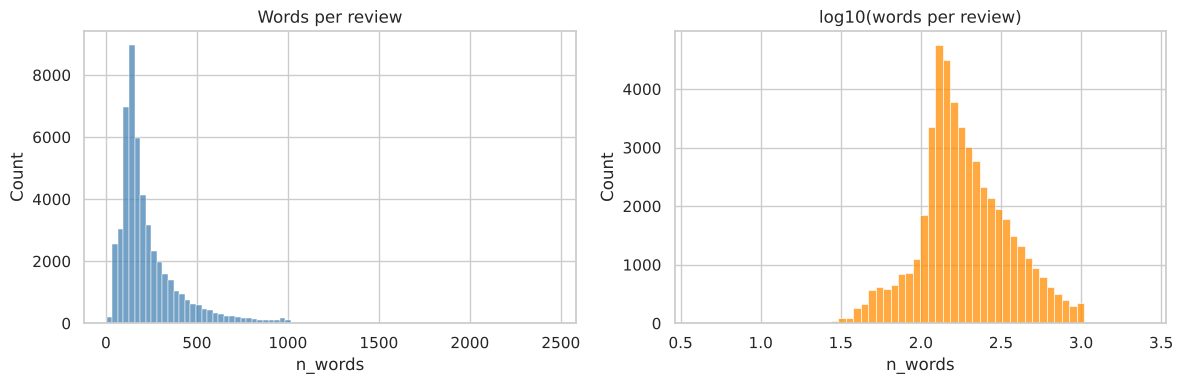

In [22]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.histplot(df['n_words'], bins=80, ax=ax[0], color='steelblue'); ax[0].set_title('Words per review'); 
sns.histplot(np.log10(df['n_words']), bins=60, ax=ax[1], color='darkorange'); ax[1].set_title('log10(words per review)')
plt.tight_layout(); plt.show()

The length distribution is right-skewed (a few very long reviews). A log scale looks near-normal.

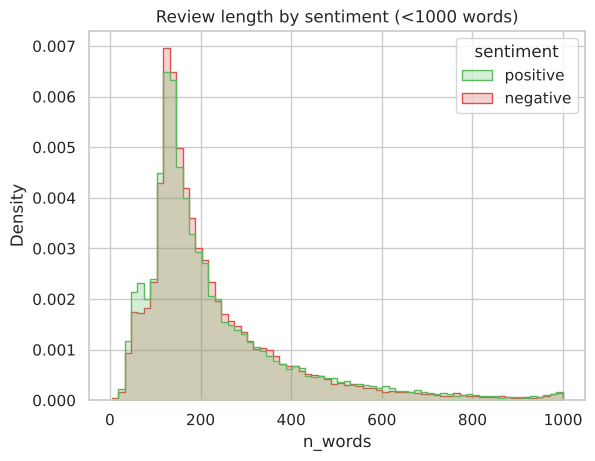

In [23]:
sns.histplot(data=df[df.n_words<1000], x='n_words', hue='sentiment', palette=PAL, bins=70, element='step', stat='density', common_norm=False)
plt.title('Review length by sentiment (<1000 words)'); plt.show()

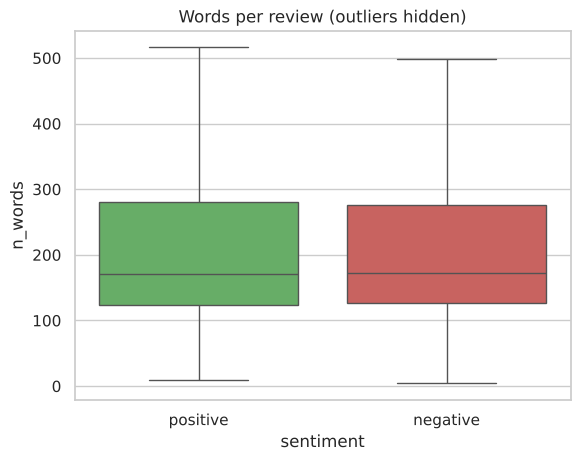

In [24]:
sns.boxplot(data=df, x='sentiment', y='n_words', palette=PAL, showfliers=False); plt.title('Words per review (outliers hidden)'); plt.show()

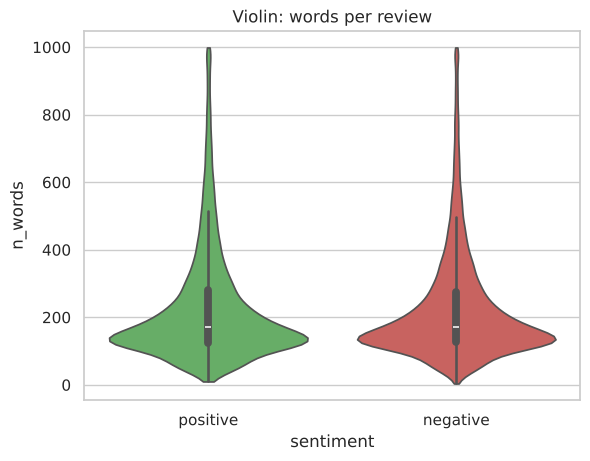

In [25]:
sns.violinplot(data=df[df.n_words<1000], x='sentiment', y='n_words', palette=PAL, cut=0); plt.title('Violin: words per review'); plt.show()

In [26]:
df.groupby('sentiment')['n_words'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,24698.0,227.2,163.3,4.0,127.0,173.0,275.8,1491.0
positive,24884.0,230.9,175.9,10.0,124.0,171.0,281.0,2459.0


### 2.1 Is the length difference statistically significant?

In [27]:
a = df.loc[df.sentiment=='positive','n_words']; b = df.loc[df.sentiment=='negative','n_words']
t, p = stats.ttest_ind(a,b,equal_var=False); u, pu = stats.mannwhitneyu(a,b)
print(f'Welch t-test: t={t:.3f}, p={p:.4g}'); print(f'Mann-Whitney U: p={pu:.4g}')

Welch t-test: t=2.376, p=0.01752
Mann-Whitney U: p=0.04902


In [28]:
def cohens_d(x,y):
    nx,ny=len(x),len(y); s=np.sqrt(((nx-1)*x.std()**2+(ny-1)*y.std()**2)/(nx+ny-2)); return (x.mean()-y.mean())/s
print('Cohen d (length):', round(cohens_d(a,b),4))

Cohen d (length): 0.0213


Positive reviews are slightly longer on average, but the effect size is **tiny** — length alone will not classify sentiment.

In [29]:
bins = pd.cut(df['n_words'], [0,50,100,150,200,300,500,3000])
df.groupby(bins)['label'].agg(['mean','count']).round(3)

,mean,count
n_words,,
"(0, 50]",0.552,1276
"(50, 100]",0.539,4994
"(100, 150]",0.495,13816
"(150, 200]",0.486,9492
"(200, 300]",0.489,9167
"(300, 500]",0.496,7047
"(500, 3000]",0.542,3790


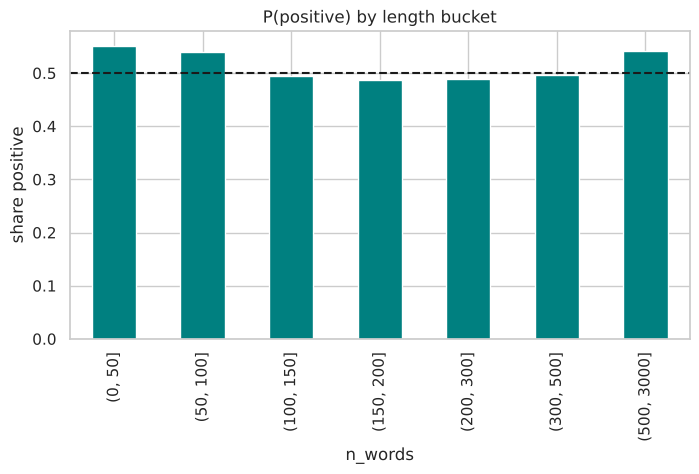

In [30]:
df.groupby(bins)['label'].mean().plot(kind='bar', color='teal', figsize=(8,4)); plt.axhline(0.5,color='k',ls='--'); plt.ylabel('share positive'); plt.title('P(positive) by length bucket'); plt.show()

In [31]:
print('Percentiles:'); print(df['n_words'].quantile([.01,.05,.25,.5,.75,.9,.95,.99]).astype(int))

Percentiles:
0.01     41
0.05     62
0.25    125
0.50    172
0.75    278
0.90    447
0.95    585
0.99    897
Name: n_words, dtype: int64


In [32]:
print('Reviews over 500 words: %.1f%%' % ((df.n_words>500).mean()*100)); print('Reviews under 30 words: %.2f%%' % ((df.n_words<30).mean()*100))

Reviews over 500 words: 7.6%
Reviews under 30 words: 0.22%


These percentiles will guide our deep-learning max sequence length (notebook 06).

## 3. Word length, sentence length, vocabulary richness

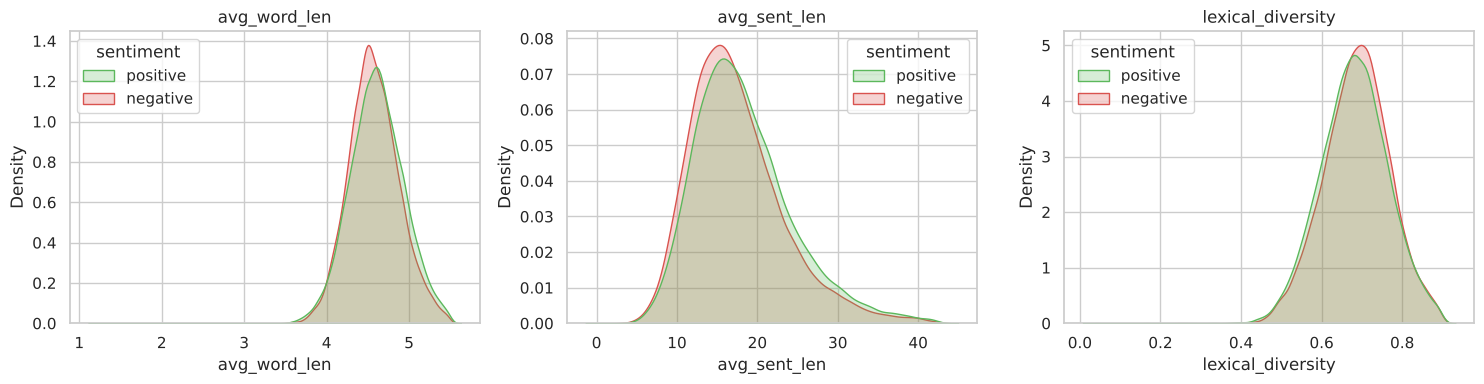

In [33]:
fig, ax = plt.subplots(1,3, figsize=(15,4))
for a_, col in zip(ax, ['avg_word_len','avg_sent_len','lexical_diversity']):
    sns.kdeplot(data=df[df[col]<df[col].quantile(.99)], x=col, hue='sentiment', palette=PAL, fill=True, common_norm=False, ax=a_); a_.set_title(col)
plt.tight_layout(); plt.show()

In [34]:
df.groupby('sentiment')[['avg_word_len','avg_sent_len','lexical_diversity','n_unique_words']].mean().round(3)

,avg_word_len,avg_sent_len,lexical_diversity,n_unique_words
sentiment,,,,
negative,4.581,18.008,0.689,146.249
positive,4.621,18.868,0.683,146.328


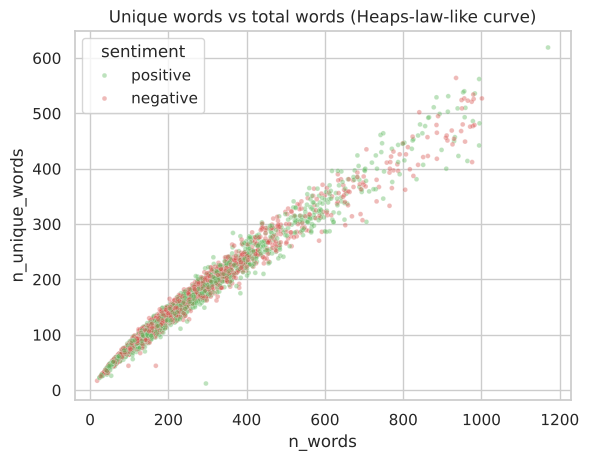

In [35]:
sns.scatterplot(data=df.sample(4000, random_state=1), x='n_words', y='n_unique_words', hue='sentiment', palette=PAL, alpha=.4, s=12); plt.title('Unique words vs total words (Heaps-law-like curve)'); plt.show()

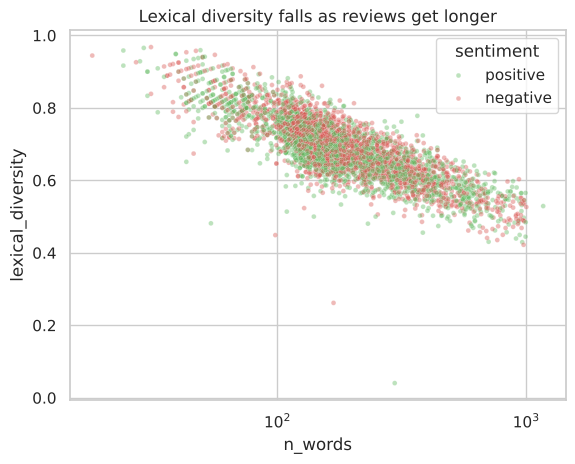

In [36]:
sns.scatterplot(data=df.sample(4000, random_state=1), x='n_words', y='lexical_diversity', hue='sentiment', palette=PAL, alpha=.4, s=12); plt.xscale('log'); plt.title('Lexical diversity falls as reviews get longer'); plt.show()

## 4. Punctuation & emphasis

In [37]:
punct = df.groupby('sentiment')[['n_exclaim','n_question','n_ellipsis','n_quotes','n_parens','n_digits']].mean().round(3).T; punct

sentiment,negative,positive
n_exclaim,1.027,0.930
n_question,0.909,0.387
n_ellipsis,0.594,0.400
n_quotes,2.738,2.538
n_parens,2.712,2.924
n_digits,3.155,3.322


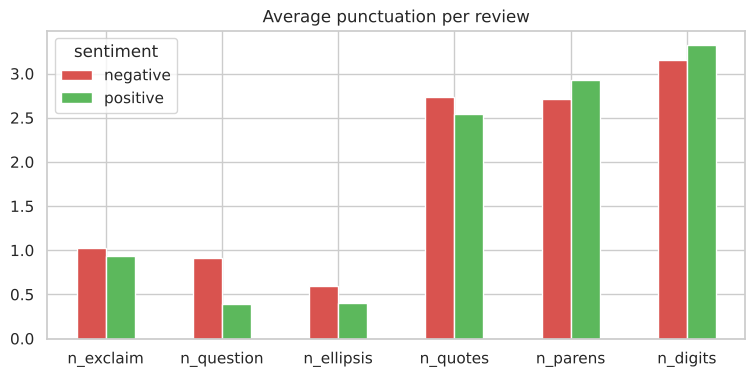

In [38]:
punct.plot(kind='bar', color=[PAL['negative'],PAL['positive']], figsize=(9,4)); plt.title('Average punctuation per review'); plt.xticks(rotation=0); plt.show()

In [39]:
for col in ['n_exclaim','n_question']:
    print(col, '— share with at least one:', df.groupby('sentiment')[col].apply(lambda s:(s>0).mean()).round(3).to_dict())

n_exclaim — share with at least one: {'negative': 0.355, 'positive': 0.339}
n_question — share with at least one: {'negative': 0.377, 'positive': 0.215}


In [40]:
ex = df.groupby(df['n_exclaim'].clip(upper=8))['label'].agg(['mean','count']).round(3); ex

,mean,count
n_exclaim,,
0,0.508,32381
1,0.503,7876
2,0.506,3557
3,0.471,2067
4,0.473,1160
5,0.452,683
6,0.475,505
7,0.450,331
8,0.442,1022


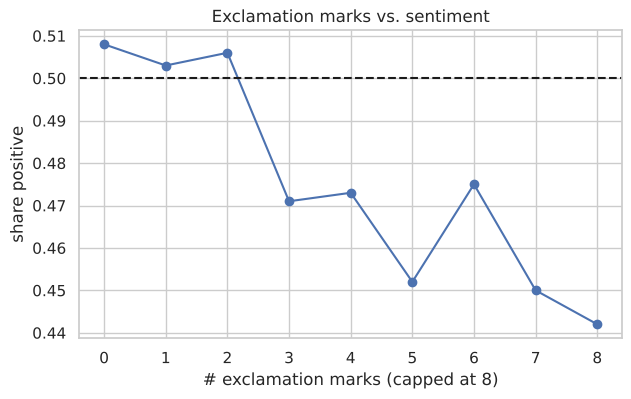

In [41]:
ex['mean'].plot(marker='o', figsize=(7,4)); plt.axhline(.5,color='k',ls='--'); plt.xlabel('# exclamation marks (capped at 8)'); plt.ylabel('share positive'); plt.title('Exclamation marks vs. sentiment'); plt.show()

## 5. Capital letters (shouting)

In [42]:
df.groupby('sentiment')[['n_upper_words','pct_upper_chars']].mean().round(3)

,n_upper_words,pct_upper_chars
sentiment,,
negative,1.971,2.781
positive,1.689,2.865


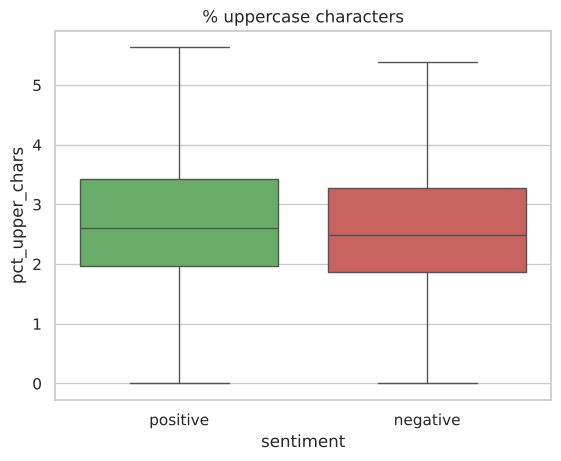

In [43]:
sns.boxplot(data=df, x='sentiment', y='pct_upper_chars', palette=PAL, showfliers=False); plt.title('% uppercase characters'); plt.show()

In [44]:
df.nlargest(3,'n_upper_words')[['text','n_upper_words','sentiment']].assign(text=lambda d: d.text.str[:200])

,text,n_upper_words,sentiment
33902,Kareena Kapoor in a bikini hmmmmmmmm. Akshay K...,154,negative
45150,This serial is interesting to watch as an MST3...,148,negative
33142,"Look, I've practically lost all hope in Nickel...",147,negative


## 6. Correlations between the numeric features

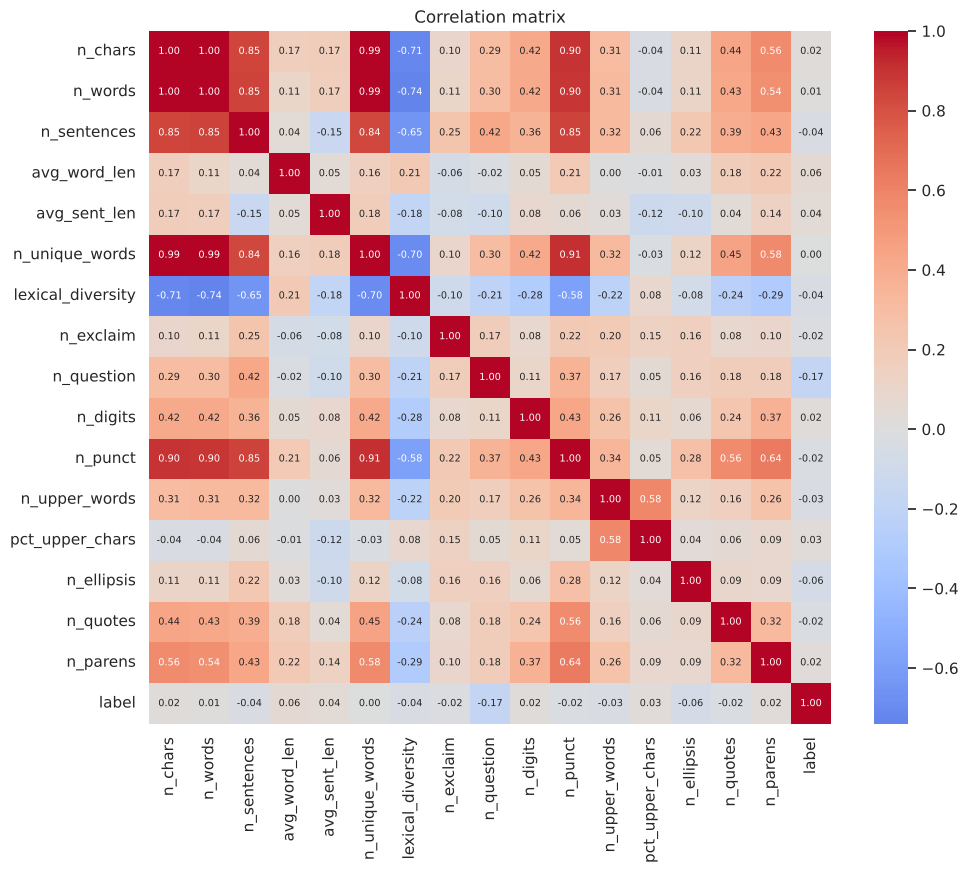

In [45]:
corr = df[feats+['label']].corr()
plt.figure(figsize=(11,9)); sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size':7}); plt.title('Correlation matrix'); plt.show()

In [46]:
corr['label'].drop('label').sort_values().to_frame('corr with sentiment').round(3)

,corr with sentiment
n_question,-0.171
n_ellipsis,-0.063
n_sentences,-0.039
lexical_diversity,-0.039
n_upper_words,-0.034
n_quotes,-0.021
n_punct,-0.020
n_exclaim,-0.017
n_unique_words,0.000
n_words,0.011


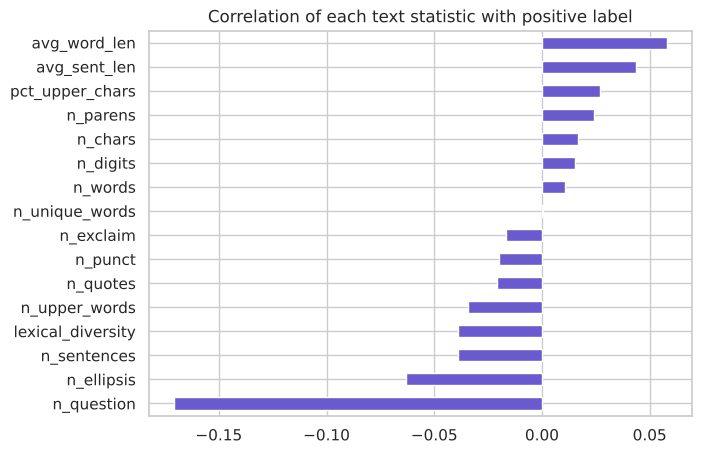

In [47]:
corr['label'].drop('label').sort_values().plot(kind='barh', figsize=(7,5), color='slateblue'); plt.title('Correlation of each text statistic with positive label'); plt.show()

Every text-statistic is only weakly correlated (|r| < 0.1) with the label. **The signal is in the *words*, not the length/punctuation** — the reason we need NLP models.

## 7. How well do these statistics alone predict sentiment?

In [48]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
Xtr,Xte,ytr,yte = train_test_split(df[feats], df['label'], test_size=.2, stratify=df['label'], random_state=42)
base_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr,ytr)
print('Logistic regression on text-stats only: accuracy =', round(base_lr.score(Xte,yte),4))

Logistic regression on text-stats only: accuracy = 0.6157


In [49]:
rf = RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1).fit(Xtr,ytr)
print('Random forest on text-stats only: accuracy =', round(rf.score(Xte,yte),4))

Random forest on text-stats only: accuracy = 0.6244


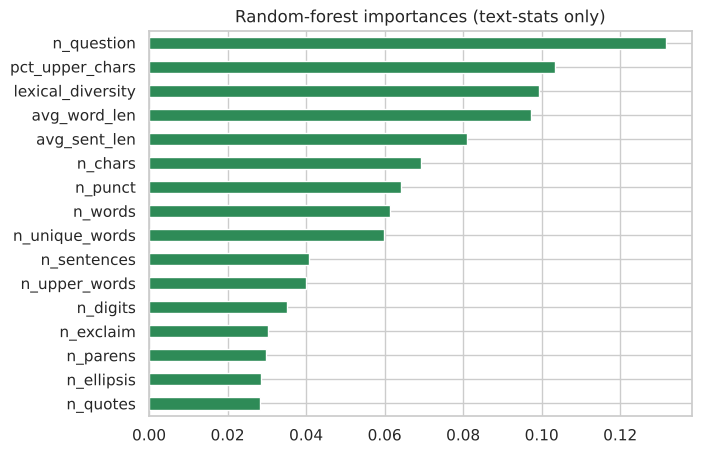

In [50]:
pd.Series(rf.feature_importances_, index=feats).sort_values().plot(kind='barh', figsize=(7,5), color='seagreen'); plt.title('Random-forest importances (text-stats only)'); plt.show()

With zero knowledge of *which* words are used, we reach only ~62% accuracy (chance = 50%). Remember this baseline — a bag-of-words model will beat it by a wide margin.

## 8. Outliers

In [51]:
q1,q3 = df.n_words.quantile([.25,.75]); iqr=q3-q1; hi=q3+1.5*iqr
print('IQR upper fence:', hi, '| outliers:', (df.n_words>hi).sum(), f'({(df.n_words>hi).mean()*100:.1f}%)')

IQR upper fence: 507.5 | outliers: 3666 (7.4%)


In [52]:
df.nsmallest(5,'n_words')[['text','n_words','sentiment']]

,text,n_words,sentiment
28785,Primary plot!Primary direction!Poor interpreta...,4,negative
27399,"Read the book, forget the movie!",6,negative
13081,"More suspenseful, more subtle, much, much more...",8,negative
40543,I hope this group of film-makers never re-unites.,8,negative
30908,"What a script, what a story, what a mess!",9,negative


In [53]:
df.nlargest(3,'n_words')[['n_words','sentiment']]

,n_words,sentiment
31309,2459,positive
40247,2235,positive
31265,2111,positive


In [54]:
print(df.loc[df.n_words>hi,'sentiment'].value_counts(normalize=True).round(3))

sentiment
positive    0.542
negative    0.458
Name: proportion, dtype: float64


Very long reviews are real (not errors), so we keep them; deep-learning models will simply truncate.

In [55]:
df.drop(columns=['text']).to_csv('data/imdb_with_stats.csv', index=False); print('saved')

saved


## 9. Summary
- Reviews: median ≈ 172 words, heavy right tail (99th percentile ≈ 900 words).
- Positive reviews are marginally longer; differences are statistically significant but practically small.
- Punctuation / capitals / length features alone give ≈ 62% accuracy — the sentiment signal is in the vocabulary.

**Next:** [03 – Vocabulary & n-grams](03_eda_vocabulary_ngrams.ipynb)